# TP2: Odd or Even? A Deep Network from Scratch

**Deadline:** 27/10/2026. **Submit:** `TP2_Name_StudentID_group.ipynb` for example `TP2_DORN_Dawin_e20200129_I4_AMSA.ipynb` by my email: dorn.dawin@gmail.com.

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


## Part 0 · Setup

In [3]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.14.1


## Part 1 · The toolbox (given)
These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [4]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

100.0%
100.0%
100.0%
100.0%


train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


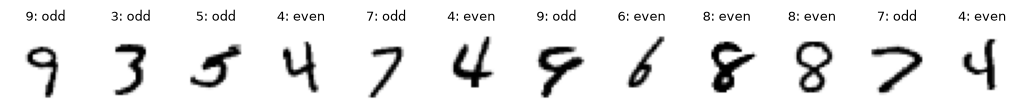

In [ ]:
# Fix: Yann LeCun's original server returns 404. Use Google's reliable mirror:
torchvision.datasets.mnist.MNIST.mirrors = [
    'https://storage.googleapis.com/cvdf-datasets/mnist/',
]

# download MNIST dataset
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

# convert to Odd vs. Even classification (1 = odd, 0 = even)
def make_odd_even(dataset, idx): 
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255 # change shape from (N, 28, 28) to (N, 784) and scale to [0, 1]
    digits = dataset.targets[idx] # get the digit labels for the selected indices
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

# split into train, dev(val), and test sets
perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0)) # randomly shuffle 60000 sample indices so training and dev sets get a representative mix of all digits
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000]) # grabs 10000 unique images for training
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000]) # grabs the next 2000 unique images for validation (dev) set
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

# display shapes and class balance
for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

# visualize some training images with their labels
fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()

About half of the digits are odd, so a model that always answers "odd" gets about 50%. That is the baseline to beat.

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [11]:
# A = torch.rand(5, 1)  # Example boolean tensor
# (A > 0.5).float()

In [13]:
# (a) predict function
def predict(X, params):
    A, _ = L_model_forward(X, params)
    return (A > 0.5).float()

# (b) accuracy function
def accuracy(X, Y, params):
    predictions = predict(X, params)
    return (predictions == Y).float().mean().item()

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])
# (c) print the dev accuracy and the fraction predicted odd
# unteained evaluation
y_pred_dev = predict(X_dev, params0)

dev_acc = accuracy(X_dev, Y_dev, params0)
frac_odd = y_pred_dev.mean().item()

print(f"untrained network | dev accuracy {dev_acc:.3f} | predicted odd {frac_odd:.3f}")


untrained network | dev accuracy 0.576 | predicted odd 0.449


**Why evaluate an untrained network?**
- **Baseline performance:** In a balanced binary problem (odd vs. even), random guessing yields $\approx 50\%$ accuracy; getting $57.6\%$ confirms expected random behavior before any gradient descent steps.
- **Sanity check:** Ensures that `predict`, `accuracy`, and the forward pass run without errors, broken shapes, or `NaN` values before investing time in training.
- **Verification of initialization:** Predicting $\approx 44.9\%$ odd shows the random weights produce a healthy balance of predictions rather than collapsing to a single class (all odd or all even).
- **Benchmark for learning:** Provides a reference point to clearly measure performance gains as the model learns during training.

## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [14]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
    # (1) initialize parameters
    params = initialize_parameters_deep(layer_dims, scale=scale, seed=seed)
    costs = []
    
    # (2) training loop
    for i in range(num_iters):
        # forward pass
        AL, caches = L_model_forward(X, params)
        
        # compute cost
        cost = compute_cost(AL, Y)
        costs.append(cost.item())
        
        # backward pass
        grads = L_model_backward(AL, Y, caches)
        
        # update parameters
        params = update_parameters(params, grads, lr)
    
        # (3) print cost if print_every is specified
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")

    # (4) return learned parameters and cost history
    return params, costs

# check: 3 iterations of [784, 20, 7, 5, 1]
params_test, costs_test = L_layer_model(
    X_train, Y_train, layer_dims=[784, 20, 7, 5, 1],
    lr=0.2, num_iters=3, print_every=1
)
print(f"number of costs: {len(costs_test)}")

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


The first cost is close to $\log 2 \approx 0.693$: an untrained network outputs about 0.5 for every image.

## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?

logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0737 | train 97.7% | dev 95.6%
4-layer              final cost 0.0063 | train 99.9% | dev 96.9%


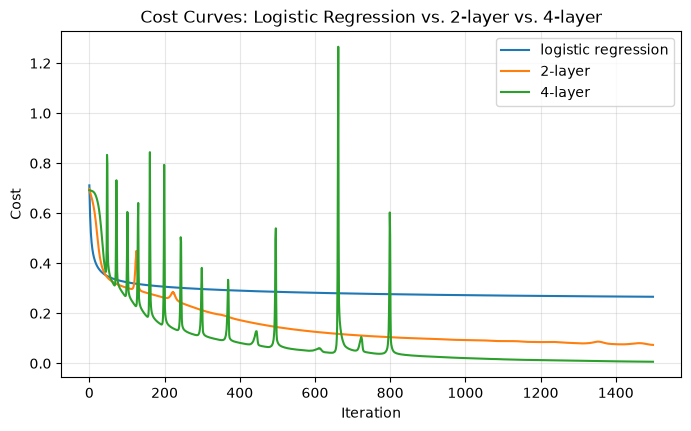

In [19]:
models = {"logistic regression": [784, 1], "2-layer": [784, 7, 1], "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}

for name, dims in models.items():
    params, costs = L_layer_model(X_train, Y_train, layer_dims=dims, lr=0.2, num_iters=1500)
    trained[name] = params
    curves[name] = costs

    train_acc = accuracy(X_train, Y_train, params)
    dev_acc = accuracy(X_dev, Y_dev, params)
    print(f"{name:20s} final cost {costs[-1]:.4f} | train {train_acc * 100:.1f}% | dev {dev_acc * 100:.1f}%")
    
# plot the three cost curves
plt.figure(figsize=(8, 4.5))
for name, costs in curves.items():
    plt.plot(costs, label=name)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(f"Cost Curves: Logistic Regression vs. 2-layer vs. 4-layer")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Task 3 · Analysis

1. **Why `[784, 1]` is exactly logistic regression:**
   In `L_model_forward` with $L = 1$, the hidden layer loop `for l in range(1, L):` runs zero times because there are no hidden layers. The function directly applies the output layer with sigmoid: $\mathbf{A}^{[1]} = \sigma(\mathbf{X}\mathbf{W}^{[1]} + \mathbf{b}^{[1]})$. This is a single linear transformation followed by a sigmoid activation, which is the exact mathematical definition of logistic regression.

2. **Why logistic regression cannot do much better on odd vs. even:**
   Logistic regression is a linear classifier whose decision boundary is a flat hyperplane in the 784-dimensional pixel space. Classifying odd vs. even digits is an inherently non-linear problem—visually similar digits with overlapping pixel distributions (such as $8$ and $9$, or $3$ and $8$) belong to opposite classes. A single linear boundary cannot separate them without hidden layers learning non-linear feature representations.

3. **Bias vs. Variance comparison:**
   - **Logistic regression** suffers mostly from **high bias (underfitting)**: its model capacity is too limited to fit the non-linear data, resulting in a high training error ($\approx 10.2\%$), though train ($89.8\%$) and dev ($89.3\%$) accuracies are close (low variance).
   - **The 4-layer network** suffers mostly from **variance (overfitting)**: it achieves nearly perfect training accuracy ($99.9\%$), but its performance drops to $96.9\%$ on dev data (a $3.0\%$ generalization gap).
   - **The 2-layer network** achieves a balanced tradeoff, drastically reducing bias compared to logistic regression while keeping the generalization gap modest ($2.2\%$).

4. **Cost curve spikes in the 4-layer network:**
   In deeper networks with constant learning rate ($\alpha = 0.2$), gradient descent can occasionally step into steep regions of the loss landscape or cross sharp ReLU thresholds, causing a temporary surge in gradient magnitude and a sudden spike in cost. The network **recovers quickly** on subsequent iterations as gradient descent steers the parameters back into a smoother descent basin.

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.

In [ ]:
# (a) Train 4-layer network with scale=0.01
params_scale_001, costs_scale_001 = L_layer_model(
    X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=1500, scale=0.01
)

dev_acc_001 = accuracy(X_dev, Y_dev, params_scale_001)
print(f"scale 0.01 | first cost {costs_scale_001[0]:.4f} | last cost {costs_scale_001[-1]:.4f} | dev {dev_acc_001 * 100:.1f}%")

# Plot cost curve next to the 4-layer curve from Task 3
plt.figure(figsize=(9, 4.5))
plt.plot(curves["4-layer"], label="4-layer (default scale = $\sqrt{1/n_{l-1}}$)", color="tab:blue")
plt.plot(costs_scale_001, label="4-layer (scale = 0.01)", color="tab:red", linestyle="--")

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of Weight Initialization on a 4-Layer Network")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

In [ ]:
# (a) at least four configurations: print the training and dev accuracy of each

# (b) choose on the dev accuracy only, store the parameters in best_params

# (c) test accuracy of best_params, once

## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

In [ ]:
# (a) number of errors, error rate per digit

# (b) at least 12 misclassified test images with the digit and p(odd)